# Case: Detecção de fraude
##### Autora: Ana Clara Fernandes

In [1]:
import pandas as pd 
import numpy as np 
from google.colab import files
import matplotlib.pyplot as plt


In [2]:
df = pd.read_csv("nuvem_fraud_dataset.csv", sep =";", decimal = ",")

In [3]:
df.head()

,created_at,store_name,vertical,amount,device,card_brand,city,state,lat,long,city_population,job,date_of_birth,store_lat,store_long,is_fraud
0,2019-01-01 00:00:44+00:00,"'Heller, Gutmann and Zieme'",grocery_pos,107.23,Mobile,Master Card,Orient,WA,48|8878,-118|2105,149,'Special educational needs teacher',1978-06-21 00:00:00+00:00,49|159047,-118|186462,0
1,2019-01-01 00:00:51+00:00,'Lind-Buckridge',entertainment,220.11,Mobile,Amex,Malad City,ID,42|1808,-112|262,4154,'Nature conservation officer',1962-01-19 00:00:00+00:00,43|150704,-112|154481,0
2,2019-01-01 00:07:27+00:00,'Kiehn Inc',grocery_pos,96.29,Mobile,Amex,Grenada,CA,41|6125,-122|5258,589,'Systems analyst',1945-12-21 00:00:00+00:00,41|65752,-122|230347,0
3,2019-01-01 00:09:03+00:00,'Beier-Hyatt',shopping_pos,7.77,Mobile,Visa,High Rolls Mountain Park,NM,32|9396,-105|8189,899,'Naval architect',1967-08-30 00:00:00+00:00,32|863258,-106|520205,0
4,2019-01-01 00:21:32+00:00,'Bruen-Yost',misc_pos,6.85,Web,Master Card,Freedom,WY,43|0172,-111|0292,471,"'Education officer, museum'",1967-08-02 00:00:00+00:00,43|753735,-111|454923,0


In [4]:
for c in ["lat", "long", "store_lat", "store_long"]:
    df[c] = df[c].astype(str).str.replace("|", ".", regex=False).astype(float)

In [5]:
df['created_at'] = pd.to_datetime(df['created_at'])
df['date_of_birth'] = pd.to_datetime(df['date_of_birth'])

#lat-long puro nao diz muita coisa, mas a distancia entre cliente e loja, sim
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = (np.sin((lat2 - lat1) / 2) ** 2
         + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2)
    return 6371 * 2 * np.arcsin(np.sqrt(a))

df['dist_km'] = haversine_km(df['lat'], df['long'], df['store_lat'], df['store_long'])

#Data de nascimento sozinha nao me diz mto, mas IDADE NO MOMENTO DA COMPRA, sim.
df['age'] = (df['created_at'] - df['date_of_birth']).dt.days / 365.25

# Hora da compra é uma variável clássica em modelos de fraude, com dummie de madrugada entre 22h e 5 da manha, geralmente.
df['hour'] = df['created_at'].dt.hour
df['flag_noite'] = df['hour'].isin([22, 23, 0, 1, 2, 3, 4, 5]).astype(int)

#variáveis deerivadas do dia da compra:
df['dia_semana'] = df['created_at'].dt.dayofweek
df['fim_semana'] = (df['dia_semana'] >= 5).astype(int)

#logs, para testar
df['log_amount'] = np.log1p(df['amount'])
df['log_city_pop'] = np.log1p(df['city_population'])

In [6]:
df.shape

(341519, 24)

In [7]:
df.head()

,created_at,store_name,vertical,amount,device,card_brand,city,state,lat,long,...,store_long,is_fraud,dist_km,age,hour,flag_noite,dia_semana,fim_semana,log_amount,log_city_pop
0,2019-01-01 00:00:44+00:00,"'Heller, Gutmann and Zieme'",grocery_pos,107.23,Mobile,Master Card,Orient,WA,48.8878,-118.2105,...,-118.186462,0,30.212176,40.531143,0,1,1,0,4.684259,5.010635
1,2019-01-01 00:00:51+00:00,'Lind-Buckridge',entertainment,220.11,Mobile,Amex,Malad City,ID,42.1808,-112.2620,...,-112.154481,0,108.206083,56.950034,0,1,1,0,5.398660,8.332068
2,2019-01-01 00:07:27+00:00,'Kiehn Inc',grocery_pos,96.29,Mobile,Amex,Grenada,CA,41.6125,-122.5258,...,-122.230347,0,25.059079,73.029432,0,1,1,0,4.577696,6.380123
3,2019-01-01 00:09:03+00:00,'Beier-Hyatt',shopping_pos,7.77,Mobile,Visa,High Rolls Mountain Park,NM,32.9396,-105.8189,...,-106.520205,0,66.021685,51.340178,0,1,1,0,2.171337,6.802395
4,2019-01-01 00:21:32+00:00,'Bruen-Yost',misc_pos,6.85,Web,Master Card,Freedom,WY,43.0172,-111.0292,...,-111.454923,0,88.830984,51.416838,0,1,1,0,2.060514,6.156979


#### Analisando as 16 colunas do df

In [8]:
df.columns

Index(['created_at', 'store_name', 'vertical', 'amount', 'device',
       'card_brand', 'city', 'state', 'lat', 'long', 'city_population', 'job',
       'date_of_birth', 'store_lat', 'store_long', 'is_fraud', 'dist_km',
       'age', 'hour', 'flag_noite', 'dia_semana', 'fim_semana', 'log_amount',
       'log_city_pop'],
      dtype='object')

In [9]:
## data_venda
print( "de: ",df['created_at'].min())
print("até: ", df['created_at'].max())

#ação necessária: separar data e hora
##como estamos falando de fraude, pelo menos a faixa horaria em que a compra ocorre deve ser testada no modelo (madrugada é mais propensa a fraude?)
## data é importante para entender movimentos sazonais

de:  2019-01-01 00:00:44+00:00
até:  2020-12-31 23:59:24+00:00


In [10]:
df['store_name'].value_counts()

#693 linhas - alta granularidade para usar num modelo unico.


,count
store_name,
'Kilback LLC',1156
'Cormier LLC',988
'Schumm PLC',933
'Dickinson Lt',898
'Kuhn LLC',897
...,...
'Johnston-Caspe',194
'Ebert-Daugherty',191
'Jerde-Hermann',187


In [11]:
df['vertical'].value_counts()

# 14 grupos - dá para usar como categoria
# numa implementação em produção, é necessário avaliar se é viável ou se melhora o resultado fazer um modelo por vertical

,count
vertical,
gas_transport,35307
grocery_pos,32927
home,32702
shopping_pos,30499
kids_pets,29860
shopping_net,26538
personal_care,24542
entertainment,24329
food_dining,23156


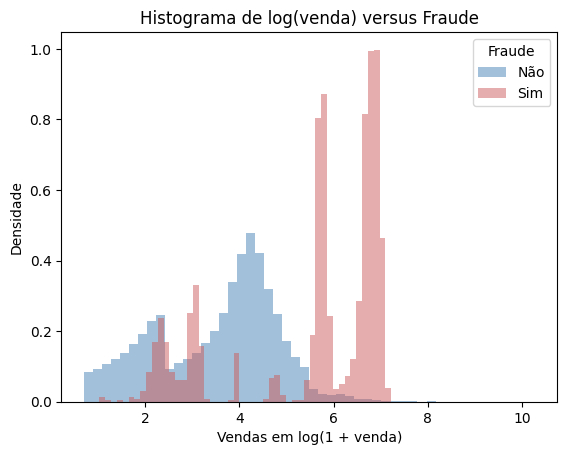

In [12]:

cores = { 0: "steelblue", 1: "indianred"}
nomes = {0: "Não", 1: "Sim"}
for rotulo, grupo in df.groupby("is_fraud"):
    valores = np.log1p(grupo["amount"].dropna())
    plt.hist(valores, bins=50, alpha=0.5, density=True, color=cores[rotulo],  label=nomes[rotulo])
plt.legend(title="Fraude")
plt.title("Histograma de log(venda) versus Fraude")
plt.xlabel("Vendas em log(1 + venda)")
plt.ylabel("Densidade")
plt.show()

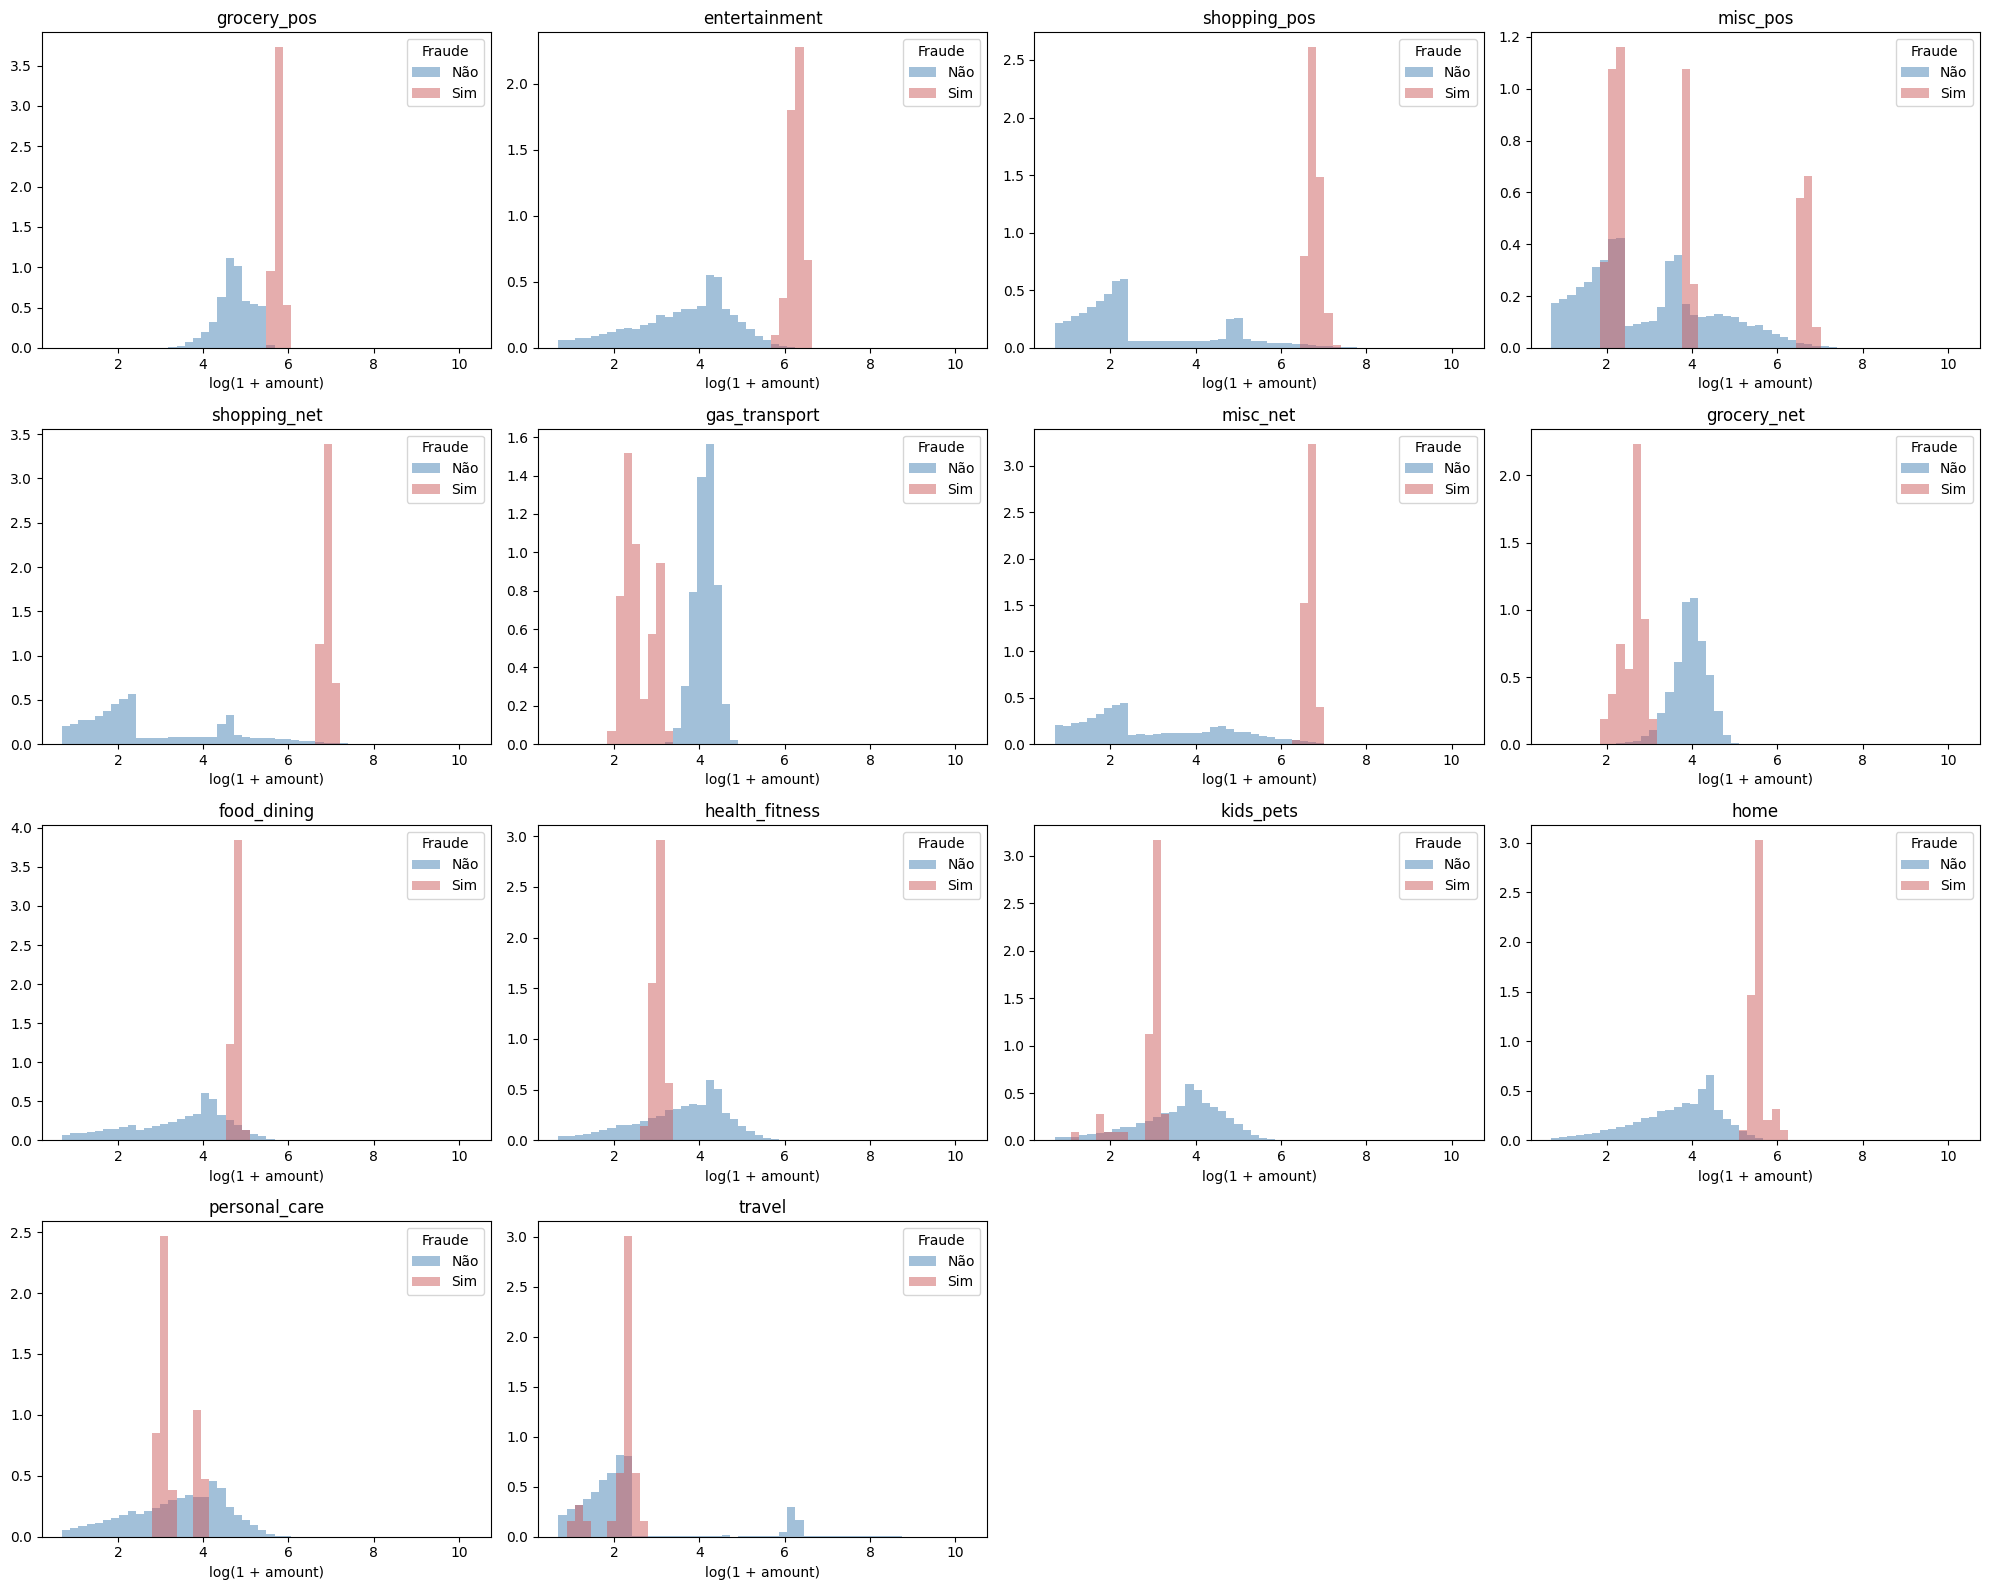

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# Ajuste para normalizar as áreas e enxergar padrões
categorias = df["vertical"].dropna().unique()
n = len(categorias)
colunas = 4
linhas = int(np.ceil(n / colunas))

fig, eixos = plt.subplots(linhas, colunas, figsize=(5 * colunas, 4 * linhas), squeeze=False)
eixos = eixos.flatten()

# bins compartilhados para a comparação ser justa entre painéis
bins = np.histogram_bin_edges(np.log1p(df["amount"].dropna()), bins=50)

for ax, cat in zip(eixos, categorias):
    sub = df[df["vertical"] == cat]
    for rotulo, grupo in sub.groupby("is_fraud"):
        ax.hist(np.log1p(grupo["amount"].dropna()), bins=bins, alpha=0.5,
                density=True, color=cores[rotulo], label=nomes[rotulo])
    ax.set_title(str(cat))
    ax.set_xlabel("log(1 + amount)")
    ax.legend(title="Fraude")

# esconde painéis vazios da última linha
for ax in eixos[n:]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

In [14]:
contagem = df.groupby(["device", "is_fraud"]).size().unstack(fill_value=0)


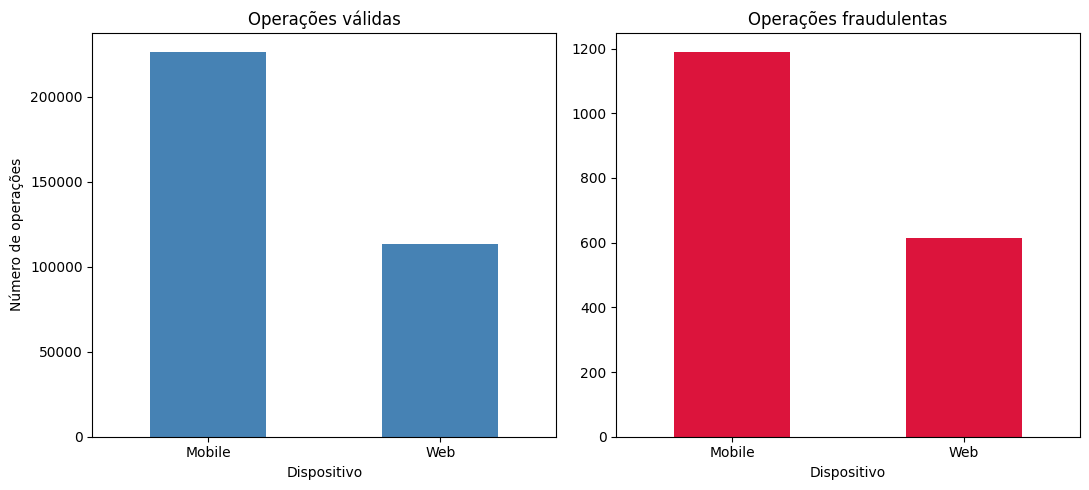

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5))

contagem[0].plot(kind="bar", ax=ax1, color="steelblue")
ax1.set_title("Operações válidas")
ax1.set_ylabel("Número de operações")

contagem[1].plot(kind="bar", ax=ax2, color="crimson")
ax2.set_title("Operações fraudulentas")

for ax in (ax1, ax2):
    ax.set_xlabel("Dispositivo")
    ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

In [16]:
df['card_brand'].value_counts()

,count
card_brand,
Visa,170520
Master Card,113945
Amex,57054


In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def analise_bivariada(df, alvo="is_fraud", max_categorias=30, graficos=True):
    d = df.copy()
    d[alvo] = d[alvo].astype(int)          # garante 0/1
    taxa_geral = d[alvo].mean() * 100       # taxa de chargeback da base

    # --- separa as colunas por tipo ---
    cols = [c for c in d.columns if c not in ('alvo', 'lat', 'long', 'store_lat', 'store_long')] # tiro o alvo
    numericas = [c for c in cols
                 if pd.api.types.is_numeric_dtype(d[c]) and not pd.api.types.is_bool_dtype(d[c])]
    categoricas, excluidas = [], []
    for c in cols:
        if c in numericas:
            continue
        if d[c].nunique(dropna=False) <= max_categorias:
            categoricas.append(c)
        else:
            excluidas.append(c)

    print(f"Numéricas ({len(numericas)}): {numericas}")
    print(f"Categóricas ({len(categoricas)}): {categoricas}")
    print(f"Excluídas por ter mais de {max_categorias} categorias ({len(excluidas)}): {excluidas}")

    ########## colunas numéricas ################
    partes = []
    for c in numericas:
        t = d.groupby(alvo)[c].agg(
            n="count",
            nulos=lambda s: s.isna().sum(),
            media="mean",
            desvio="std",
            minimo="min",
            p25=lambda s: s.quantile(0.25),
            mediana="median",
            p75=lambda s: s.quantile(0.75),
            maximo="max",
        )
        t.insert(0, "variavel", c)
        partes.append(t.reset_index())
    resumo_num = pd.concat(partes, ignore_index=True) if partes else pd.DataFrame()

    ########### Categoricas ######################
    tabelas_cat = {}
    for c in categoricas:
        x = d[c].astype(object).where(d[c].notna(), "(nulo)")
        t = d.groupby(x)[alvo].agg(operacoes="size", fraudes="sum", taxa_fraude="mean")
        t["taxa_fraude"] *= 100
        t["pct_do_volume"] = t["operacoes"] / len(d) * 100
        tabelas_cat[c] = t.sort_values("taxa_fraude", ascending=False)

    # --- gráficos ---
    if graficos:
        colunas = 4

        if numericas:
            linhas = int(np.ceil(len(numericas) / colunas))
            fig, eixos = plt.subplots(linhas, colunas, figsize=(5 * colunas, 4 * linhas), squeeze=False)
            eixos = eixos.flatten()
            for ax, c in zip(eixos, numericas):
                dados = [d.loc[d[alvo] == k, c].dropna() for k in (0, 1)]
                bp = ax.boxplot(dados, patch_artist=True)
                for caixa, cor in zip(bp["boxes"], ["steelblue", "crimson"]):
                    caixa.set_facecolor(cor)
                    caixa.set_alpha(0.6)
                ax.set_xticklabels(["Não", "Sim"])
                titulo = c
                if d[c].min() >= 0 and d[c].skew() > 2:     # cauda longa: escala symlog
                    ax.set_yscale("symlog")
                    titulo += " (symlog)"
                ax.set_title(titulo)
                ax.set_xlabel("Fraude")
            for ax in eixos[len(numericas):]:
                ax.set_visible(False)
            plt.tight_layout()
            plt.show()

        if categoricas:
            linhas = int(np.ceil(len(categoricas) / colunas))
            fig, eixos = plt.subplots(linhas, colunas, figsize=(5 * colunas, 4 * linhas), squeeze=False)
            eixos = eixos.flatten()
            for ax, c in zip(eixos, categoricas):
                t = tabelas_cat[c]
                ax.bar(t.index.astype(str), t["taxa_fraude"], color="crimson", alpha=0.7)
                ax.axhline(taxa_geral, ls="--", color="gray", label="taxa geral")
                ax.set_title(c)
                ax.set_ylabel("Taxa de fraude (%)")
                ax.tick_params(axis="x", rotation=45)
                plt.setp(ax.get_xticklabels(), ha="right")
                ax.legend()
            for ax in eixos[len(categoricas):]:
                ax.set_visible(False)
            plt.tight_layout()
            plt.show()

    return {
        "resumo_numericas": resumo_num,
        "tabelas_categoricas": tabelas_cat,
        "excluidas": excluidas,
    }

Numéricas (11): ['amount', 'city_population', 'is_fraud', 'dist_km', 'age', 'hour', 'flag_noite', 'dia_semana', 'fim_semana', 'log_amount', 'log_city_pop']
Categóricas (4): ['vertical', 'device', 'card_brand', 'state']
Excluídas por ter mais de 30 categorias (5): ['created_at', 'store_name', 'city', 'job', 'date_of_birth']


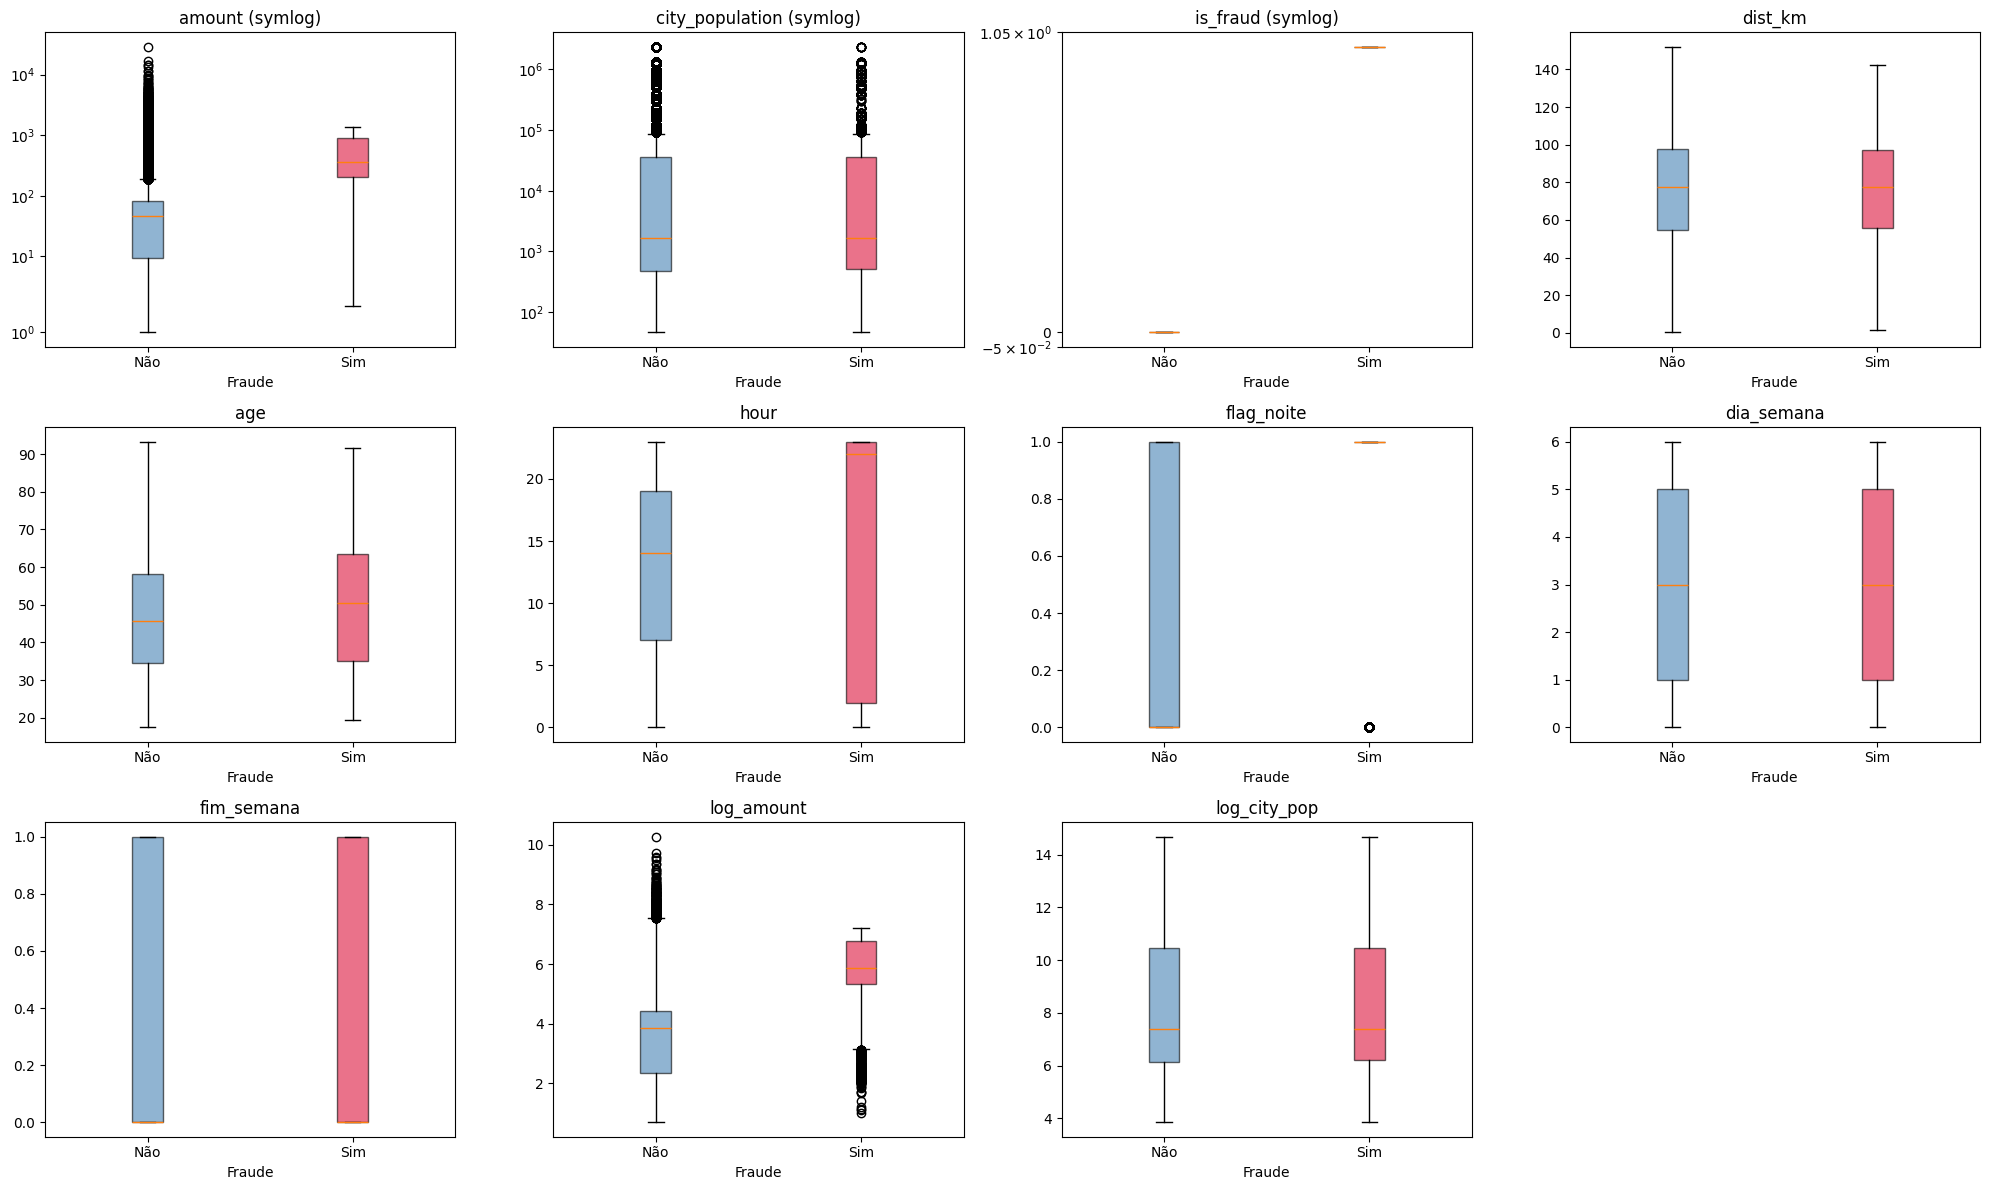

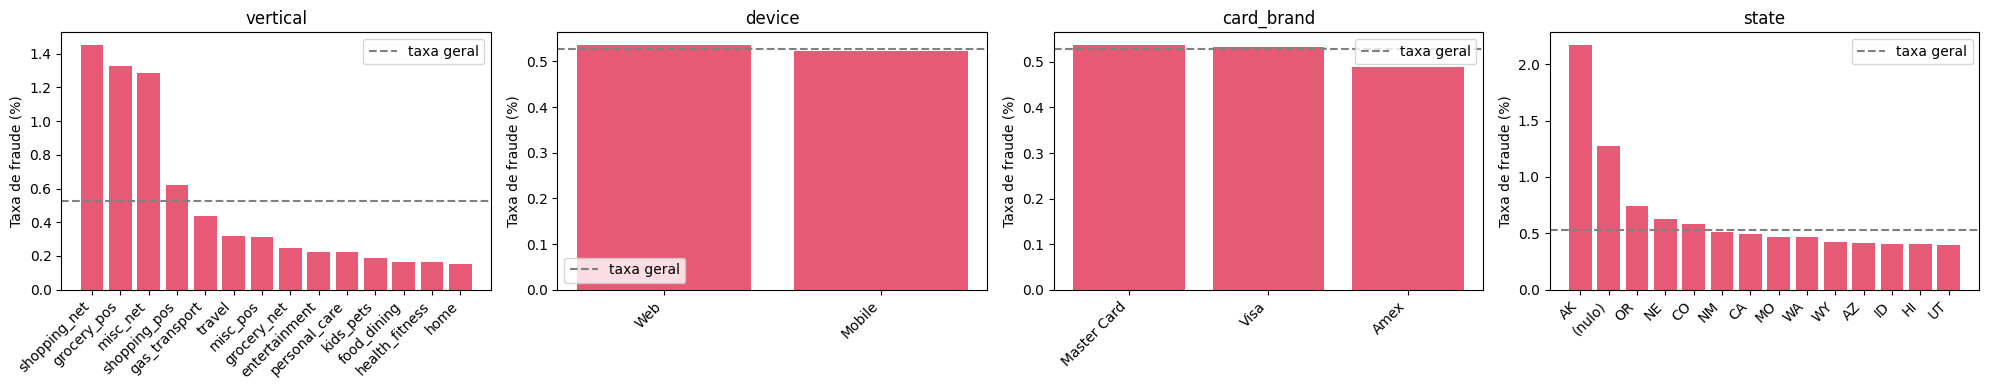

,operacoes,fraudes,taxa_fraude,pct_do_volume
state,,,,
AK,2989,65,2.174640,0.875208
(nulo),943,12,1.272534,0.276119
OR,26487,197,0.743761,7.755645
NE,34514,216,0.625833,10.106026
CO,19805,115,0.580661,5.799092
NM,23475,121,0.515442,6.873702
CA,80738,402,0.497907,23.640852
MO,55069,258,0.468503,16.124725
WA,27112,126,0.464739,7.938651


In [18]:
res = analise_bivariada(df, alvo="is_fraud")

res["resumo_numericas"]                        # tabela de sumarização por classe
res["tabelas_categoricas"]["vertical"]   
res["tabelas_categoricas"]["device"] 
res["tabelas_categoricas"]["card_brand"] 
res["tabelas_categoricas"]["state"] 

In [19]:
# excluidas na analise automatizada pelo numero de categorias
# Excluídas por ter mais de 30 categorias (9): ['created_at', 'store_name', 'city', 'lat', 'long', 'job', 'date_of_birth', 'store_lat', 'store_long']

#creates_at -> data_hora_transação
# store_name -> nome da loja
# city -> cidade e estado

df.columns

Index(['created_at', 'store_name', 'vertical', 'amount', 'device',
       'card_brand', 'city', 'state', 'lat', 'long', 'city_population', 'job',
       'date_of_birth', 'store_lat', 'store_long', 'is_fraud', 'dist_km',
       'age', 'hour', 'flag_noite', 'dia_semana', 'fim_semana', 'log_amount',
       'log_city_pop'],
      dtype='object')

In [20]:
df['state'].value_counts()

,count
state,
CA,80738
MO,55069
NE,34514
WY,27855
WA,27112
OR,26487
NM,23475
CO,19805
AZ,15424


In [21]:

# distancia entre cliente e loja
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = (np.sin((lat2 - lat1) / 2) ** 2
         + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2)
    return 6371 * 2 * np.arcsin(np.sqrt(a))

# 3. Nova coluna com a distância entre comprador e loja
df["dist_km"] = haversine_km(df["lat"], df["long"], df["store_lat"], df["store_long"])

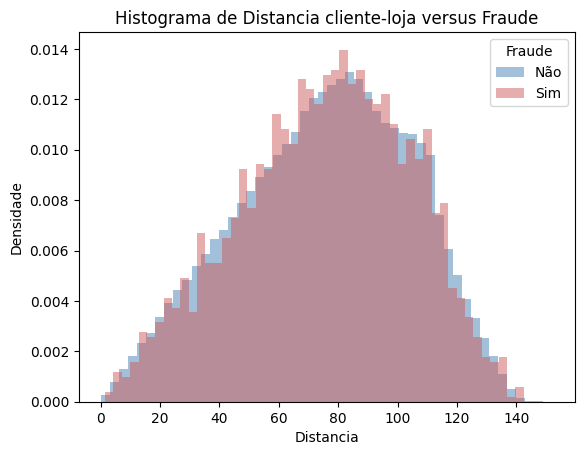

In [22]:

cores = { 0: "steelblue", 1: "indianred"}
nomes = {0: "Não", 1: "Sim"}
for rotulo, grupo in df.groupby("is_fraud"):
    valores = grupo["dist_km"].dropna()
    plt.hist(valores, bins=50, alpha=0.5, density=True, color=cores[rotulo],  label=nomes[rotulo])
plt.legend(title="Fraude")
plt.title("Histograma de Distancia cliente-loja versus Fraude")
plt.xlabel("Distancia")
plt.ylabel("Densidade")
plt.show()


# Aparentemente existem outliers no plot normalizado - Mas isso pode depender da regiao que a loja está.

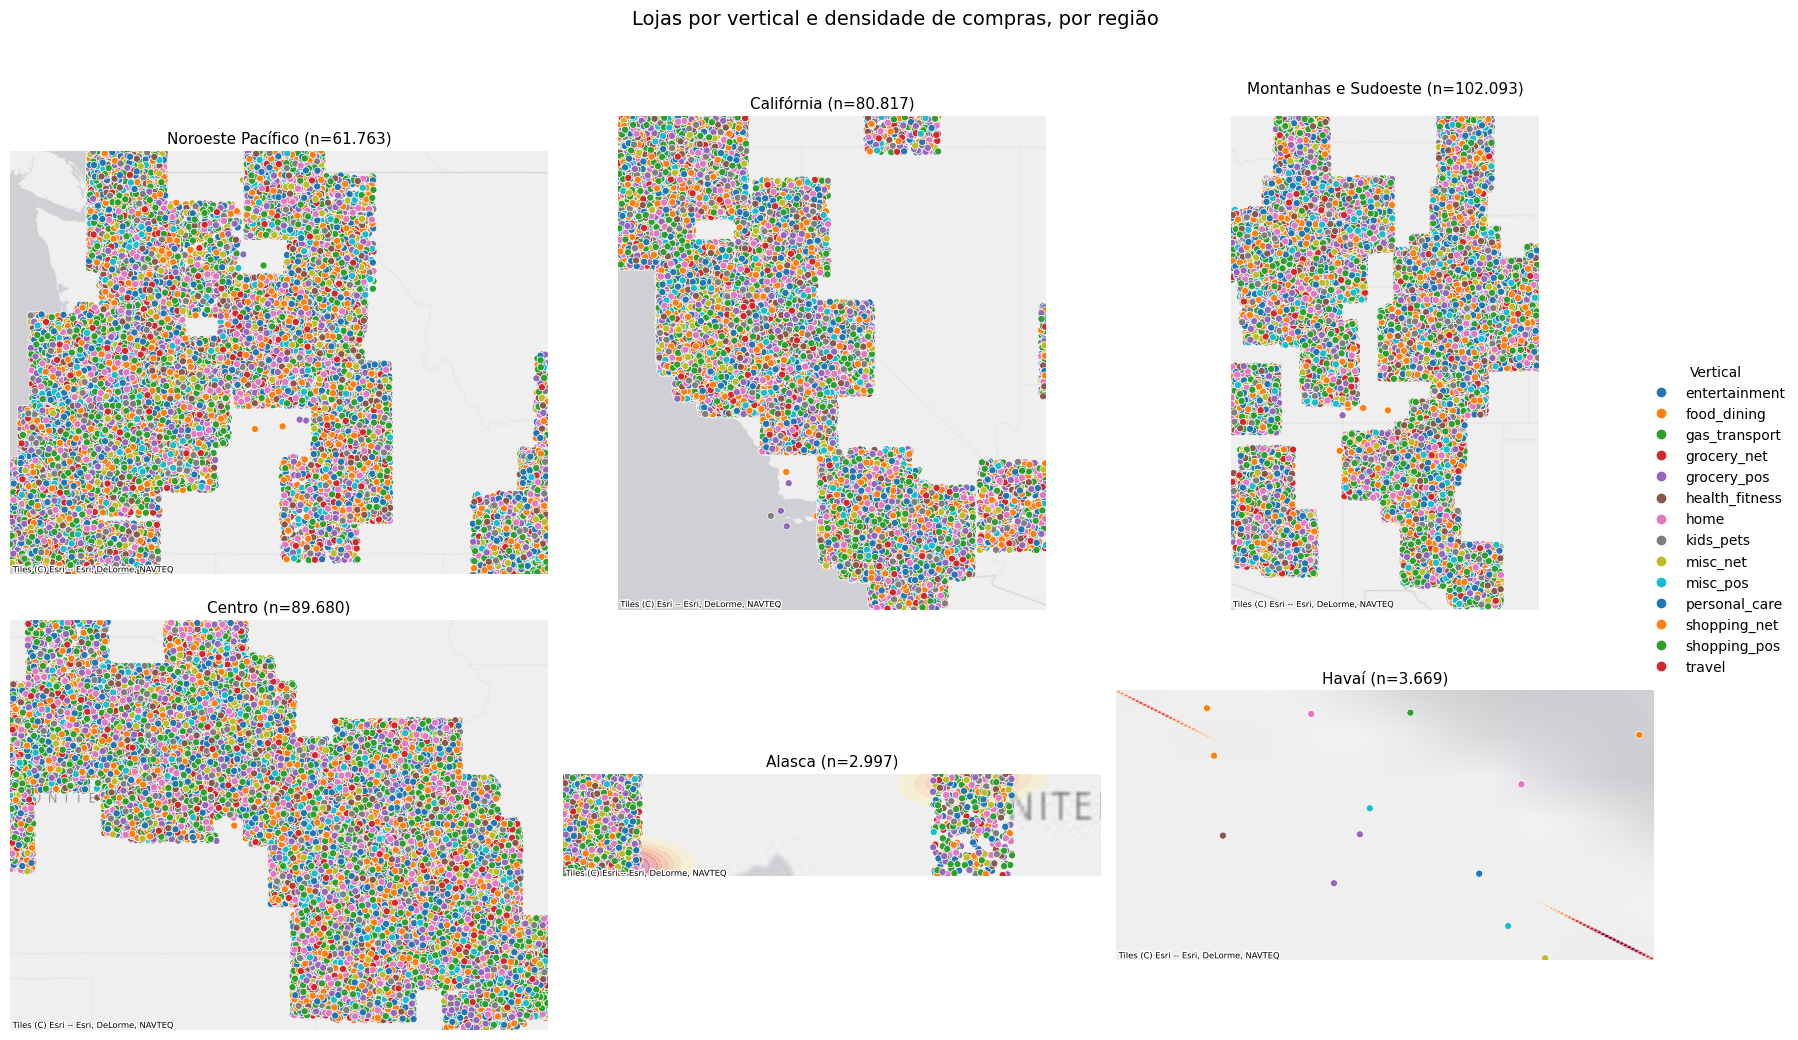

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
import contextily as cx

# ------------------------------------------------------------
# 1) Agrupamento de estados em regiões
# ------------------------------------------------------------
regioes = {
    'Noroeste Pacífico':    ['WA', 'OR', 'ID'],
    'Califórnia':           ['CA'],
    'Montanhas e Sudoeste': ['CO', 'UT', 'WY', 'NM', 'AZ'],
    'Centro':               ['NE', 'MO'],
    'Alasca':               ['AK'],
    'Havaí':                ['HI'],
}
uf2reg = {uf: r for r, ufs in regioes.items() for uf in ufs}

# Zoom do basemap por região (None = automático). Se algum painel
# demorar ou falhar, reduza o valor (5 a 7 para regiões; 4 para o Alasca).
ZOOM = {
    'Noroeste Pacífico':    6,
    'Califórnia':           6,
    'Montanhas e Sudoeste': 5,
    'Centro':               6,
    'Alasca':               4,
    'Havaí':                7,
}

df = df.copy()
df['regiao'] = df['state'].map(uf2reg)

# Estados nulos: atribuo à região do centroide mais próximo (lat/long do cliente).
# Os centroides são calculados apenas com os estados já mapeados.
cent = df.dropna(subset=['regiao']).groupby('regiao')[['lat', 'long']].mean()
sem = df['regiao'].isna() & df['lat'].notna() & df['long'].notna()
dist2 = ((df.loc[sem, 'lat'].values[:, None] - cent['lat'].values[None, :]) ** 2 +
         (df.loc[sem, 'long'].values[:, None] - cent['long'].values[None, :]) ** 2)
df.loc[sem, 'regiao'] = cent.index.values[dist2.argmin(axis=1)]

# Checagem: UFs presentes na base que ficaram fora do dicionário
fora = df.loc[df['state'].notna() & ~df['state'].isin(uf2reg), 'state'].value_counts()
if len(fora):
    print('UFs fora do dicionário (incluir em alguma região):')
    print(fora)

# ------------------------------------------------------------
# 2) Funções auxiliares
# ------------------------------------------------------------
def to_merc(d, x, y):
    """DataFrame com colunas lon/lat em graus -> GeoDataFrame em Web Mercator."""
    return gpd.GeoDataFrame(
        d.copy(), geometry=gpd.points_from_xy(d[x], d[y]), crs='EPSG:4326'
    ).to_crs(3857)

# Lojas únicas (o df está no nível transação)
stores = (df[['store_name', 'vertical', 'store_lat', 'store_long']]
          .dropna()
          .drop_duplicates(subset=['store_name', 'store_lat', 'store_long']))
g_st = to_merc(stores, 'store_long', 'store_lat')
gx, gy = g_st.geometry.x, g_st.geometry.y

verticais = sorted(df['vertical'].dropna().unique())
pal = dict(zip(verticais, sns.color_palette('tab10', len(verticais))))

def plot_regiao(ax, nome):
    sub = df.loc[df['regiao'] == nome, ['lat', 'long']].dropna()
    g_cu = to_merc(sub, 'long', 'lat')
    x, y = g_cu.geometry.x.values, g_cu.geometry.y.values

    # Limites: recorto 0,5% de cada ponta para outliers não esticarem o painel
    xmin, xmax = np.percentile(x, [0.5, 99.5])
    ymin, ymax = np.percentile(y, [0.5, 99.5])
    px, py = (xmax - xmin) * 0.08, (ymax - ymin) * 0.08
    ax.set_xlim(xmin - px, xmax + px)
    ax.set_ylim(ymin - py, ymax + py)
    ax.set_aspect('equal')

    # Camada 1: mancha de clientes (KDE em amostra, para não travar)
    n = min(30_000, len(x))
    idx = np.random.default_rng(42).choice(len(x), n, replace=False)
    sns.kdeplot(x=x[idx], y=y[idx], fill=True, cmap='magma_r', levels=12,
                thresh=0.08, bw_adjust=0.8, alpha=0.4, ax=ax, zorder=2)

    # Camada 2: lojas dentro da janela do painel, coloridas por vertical
    # (o df só tem o estado do cliente, então filtro pela extensão)
    m = gx.between(*ax.get_xlim()) & gy.between(*ax.get_ylim())
    ax.scatter(gx[m], gy[m], c=g_st.loc[m, 'vertical'].map(pal), s=26,
               edgecolor='white', linewidth=0.5, zorder=3)

    # Camada 0: basemap (Esri, sem chave de API)
    try:
        cx.add_basemap(ax, source=cx.providers.Esri.WorldGrayCanvas,
                       crs='EPSG:3857', zorder=0, zoom=ZOOM.get(nome),
                       attribution_size=6)
    except Exception as e:
        print(f'[{nome}] basemap não carregou: {e}')

    ax.set_axis_off()
    ax.set_title(f"{nome} (n={len(sub):,})".replace(',', '.'), fontsize=11)

# ------------------------------------------------------------
# 3) Figura: um painel por região
# ------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for ax, nome in zip(axes.ravel(), regioes):
    plot_regiao(ax, nome)

handles = [plt.Line2D([], [], marker='o', ls='', color=pal[v], label=v)
           for v in verticais]
fig.legend(handles=handles, title='Vertical', loc='center right', frameon=False)
fig.suptitle('Lojas por vertical e densidade de compras, por região', fontsize=14)
plt.tight_layout(rect=[0, 0, 0.93, 0.96])
plt.show()